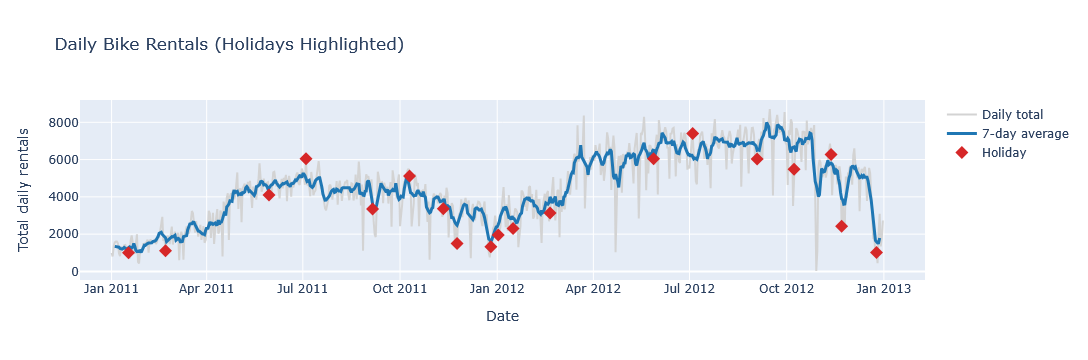

In [1]:
import pandas as pd
import plotly.express as px

bikes = pd.read_csv("hour.csv")
holidays = pd.read_csv("us_federal_holidays_2011_2012.csv", encoding="utf-8-sig")

# Convert to actual dates
bikes["dteday"] = pd.to_datetime(bikes["dteday"])
holidays["date"] = pd.to_datetime(holidays["date"], format="%d/%m/%Y")

# Drop the duplicates
holidays = (
    holidays[["date", "holiday"]]
    .rename(columns={"holiday": "holiday_name"})
    .drop_duplicates(subset=["date"])
)

# Join statment
bikes = bikes.merge(
    holidays,
    left_on="dteday",
    right_on="date",
    how="left",
    validate="many_to_one"
)

bikes["day_type"] = bikes["holiday_name"].notna().map({
    True: "Holiday",
    False: "Non-holiday"
})

daily = bikes.groupby(
    ["dteday", "day_type", "holiday_name"],
    dropna=False
).agg(
    daily_rentals=("cnt", "sum")
).reset_index()


# print(daily.head())
# print(daily["day_type"].value_counts())

# ------- We should put graphs after here -------

daily = daily.sort_values("dteday")
daily["rolling_7d"] = daily["daily_rentals"].rolling(7, center=True).mean()

fig2 = px.line(
    daily,
    x="dteday",
    y="daily_rentals",
    title="Daily Bike Rentals (Holidays Highlighted)",
    labels={"dteday": "Date", "daily_rentals": "Total daily rentals"},
)
fig2.update_traces(line=dict(color="lightgrey"), name="Daily total", showlegend=True)

# 7-day rolling average
fig2.add_scatter(
    x=daily["dteday"], y=daily["rolling_7d"],
    mode="lines", name="7-day average",
    line=dict(color="#1f77b4", width=3),
)

# Holiday markers with names on hover
hol = daily[daily["day_type"] == "Holiday"]
fig2.add_scatter(
    x=hol["dteday"], y=hol["daily_rentals"],
    mode="markers", name="Holiday",
    marker=dict(color="#d62728", size=10, symbol="diamond"),
    text=hol["holiday_name"],
    hovertemplate="%{text}<br>%{x|%d %b %Y}<br>%{y:,} rentals<extra></extra>",
)
fig2.show()